# Image Classification: a CNN from scratch, step by step

**Goal:** classify handwritten digits with a convolutional neural network written in pure NumPy, so every gradient is visible. Then show *why* convolutions beat flat models by stress-testing on shifted and noisy images.

**Contents**
1. Setup
2. The dataset: shape, labels and class balance
3. Looking at the pixels: examples, mean images and pixel statistics
4. Train / validation / test split
5. Baselines: logistic regression and an MLP on flat pixels
6. Building blocks: im2col convolution, checked against a direct loop
7. Gradient check: does backpropagation compute the right numbers?
8. Training the CNN, with and without augmentation
9. Learning curves
10. Test metrics: accuracy, macro-F1, log loss, calibration (ECE)
11. Per-class performance and the confusion matrix
12. Robustness: 1-pixel shifts and Gaussian noise
13. Explainability: learned filters, feature maps and saliency
14. Error analysis: the digits the model gets wrong
15. Where this goes next: transfer learning on real satellite photos
16. Ethics and limitations

## 1. Setup

In [1]:
import sys, time
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, confusion_matrix, classification_report
from vision.numpy_cnn import CNN, Conv2D, im2col, cross_entropy, augment, train, softmax
from vision.evaluate import load_data, shift, corruptions, ece, saliency
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.4f}".format)
np.set_printoptions(precision=3, suppress=True)

## 2. The dataset

The UCI handwritten digits set (shipped with scikit-learn): 1,797 scans of digits written by 43 people, downsampled to 8×8 greyscale with intensities 0–16. It is small enough to train a hand-written CNN on a laptop CPU in under a minute, and it is a real dataset, not a synthetic one.

In [2]:
d = load_digits()
print("images:", d.images.shape, " flat:", d.data.shape, " targets:", d.target.shape)
print("pixel value range:", d.images.min(), "to", d.images.max(), " dtype:", d.images.dtype)
df = pd.DataFrame(d.data, columns=[f"px_{r}_{c}" for r in range(8) for c in range(8)])
df["label"] = d.target
df.head()

images: (1797, 8, 8)  flat: (1797, 64)  targets: (1797,)
pixel value range: 0.0 to 16.0  dtype: float64

,px_0_0,px_0_1,px_0_2,px_0_3,px_0_4,px_0_5,px_0_6,px_0_7,px_1_0,px_1_1,px_1_2,px_1_3,px_1_4,px_1_5,px_1_6,px_1_7,px_2_0,px_2_1,px_2_2,px_2_3,px_2_4,px_2_5,px_2_6,px_2_7,px_3_0,px_3_1,px_3_2,px_3_3,px_3_4,px_3_5,px_3_6,px_3_7,px_4_0,px_4_1,px_4_2,px_4_3,px_4_4,px_4_5,px_4_6,px_4_7,px_5_0,px_5_1,px_5_2,px_5_3,px_5_4,px_5_5,px_5_6,px_5_7,px_6_0,px_6_1,px_6_2,px_6_3,px_6_4,px_6_5,px_6_6,px_6_7,px_7_0,px_7_1,px_7_2,px_7_3,px_7_4,px_7_5,px_7_6,px_7_7,label
0,0.0000,0.0000,5.0000,13.0000,9.0000,1.0000,0.0000,0.0000,0.0000,0.0000,13.0000,15.0000,10.0000,15.0000,5.0000,0.0000,0.0000,3.0000,15.0000,2.0000,0.0000,11.0000,8.0000,0.0000,0.0000,4.0000,12.0000,0.0000,0.0000,8.0000,8.0000,0.0000,0.0000,5.0000,8.0000,0.0000,0.0000,9.0000,8.0000,0.0000,0.0000,4.0000,11.0000,0.0000,1.0000,12.0000,7.0000,0.0000,0.0000,2.0000,14.0000,5.0000,10.0000,12.0000,0.0000,0.0000,0.0000,0.0000,6.0000,13.0000,10.0000,0.0000,0.0000,0.0000,0
1,0.0000,0.0000,0.0000,12.0000,13.0000,5.0000,0.0000,0.0000,0.0000,0.0000,0.0000,11.0000,16.0000,9.0000,0.0000,0.0000,0.0000,0.0000,3.0000,15.0000,16.0000,6.0000,0.0000,0.0000,0.0000,7.0000,15.0000,16.0000,16.0000,2.0000,0.0000,0.0000,0.0000,0.0000,1.0000,16.0000,16.0000,3.0000,0.0000,0.0000,0.0000,0.0000,1.0000,16.0000,16.0000,6.0000,0.0000,0.0000,0.0000,0.0000,1.0000,16.0000,16.0000,6.0000,0.0000,0.0000,0.0000,0.0000,0.0000,11.0000,16.0000,10.0000,0.0000,0.0000,1
2,0.0000,0.0000,0.0000,4.0000,15.0000,12.0000,0.0000,0.0000,0.0000,0.0000,3.0000,16.0000,15.0000,14.0000,0.0000,0.0000,0.0000,0.0000,8.0000,13.0000,8.0000,16.0000,0.0000,0.0000,0.0000,0.0000,1.0000,6.0000,15.0000,11.0000,0.0000,0.0000,0.0000,1.0000,8.0000,13.0000,15.0000,1.0000,0.0000,0.0000,0.0000,9.0000,16.0000,16.0000,5.0000,0.0000,0.0000,0.0000,0.0000,3.0000,13.0000,16.0000,16.0000,11.0000,5.0000,0.0000,0.0000,0.0000,0.0000,3.0000,11.0000,16.0000,9.0000,0.0000,2
3,0.0000,0.0000,7.0000,15.0000,13.0000,1.0000,0.0000,0.0000,0.0000,8.0000,13.0000,6.0000,15.0000,4.0000,0.0000,0.0000,0.0000,2.0000,1.0000,13.0000,13.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,15.0000,11.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,12.0000,12.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,10.0000,8.0000,0.0000,0.0000,0.0000,8.0000,4.0000,5.0000,14.0000,9.0000,0.0000,0.0000,0.0000,7.0000,13.0000,13.0000,9.0000,0.0000,0.0000,3
4,0.0000,0.0000,0.0000,1.0000,11.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,7.0000,8.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,13.0000,6.0000,2.0000,2.0000,0.0000,0.0000,0.0000,7.0000,15.0000,0.0000,9.0000,8.0000,0.0000,0.0000,5.0000,16.0000,10.0000,0.0000,16.0000,6.0000,0.0000,0.0000,4.0000,15.0000,16.0000,13.0000,16.0000,1.0000,0.0000,0.0000,0.0000,0.0000,3.0000,15.0000,10.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,16.0000,4.0000,0.0000,0.0000,4


In [3]:
df.describe().T.head(16)

,count,mean,std,min,25%,50%,75%,max
px_0_0,"1,797.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
px_0_1,"1,797.0000",0.3038,0.9072,0.0000,0.0000,0.0000,0.0000,8.0000
px_0_2,"1,797.0000",5.2048,4.7548,0.0000,1.0000,4.0000,9.0000,16.0000
px_0_3,"1,797.0000",11.8358,4.2488,0.0000,10.0000,13.0000,15.0000,16.0000
px_0_4,"1,797.0000",11.8481,4.2874,0.0000,10.0000,13.0000,15.0000,16.0000
px_0_5,"1,797.0000",5.7819,5.6664,0.0000,0.0000,4.0000,11.0000,16.0000
px_0_6,"1,797.0000",1.3623,3.3258,0.0000,0.0000,0.0000,0.0000,16.0000
px_0_7,"1,797.0000",0.1297,1.0374,0.0000,0.0000,0.0000,0.0000,15.0000
px_1_0,"1,797.0000",0.0056,0.0942,0.0000,0.0000,0.0000,0.0000,2.0000
px_1_1,"1,797.0000",1.9939,3.1962,0.0000,0.0000,0.0000,3.0000,16.0000


The first column of pixels (`px_0_0`, `px_1_0`, …) is almost always 0: the scanner cropped digits to the centre. Those pixels carry no information, which is one reason a flat linear model still does reasonably well here.

**Class balance:**

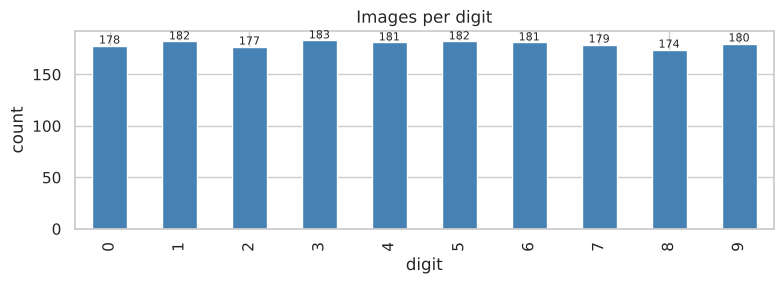

In [4]:
counts = df.label.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3))
counts.plot.bar(ax=ax, color="steelblue"); ax.set(title="Images per digit", xlabel="digit", ylabel="count")
for i, v in enumerate(counts): ax.text(i, v + 2, v, ha="center", fontsize=8)
plt.tight_layout();

In [5]:
counts.to_frame("count").assign(share=lambda t: t["count"] / t["count"].sum()).T

label,0,1,2,3,4,5,6,7,8,9
count,178.0000,182.0000,177.0000,183.0000,181.0000,182.0000,181.0000,179.0000,174.0000,180.0000
share,0.0991,0.1013,0.0985,0.1018,0.1007,0.1013,0.1007,0.0996,0.0968,0.1002


Classes are balanced (174–183 each, roughly 10% apiece), so plain accuracy is a fair headline metric. We still report macro-F1, which would expose a weak class that accuracy might hide.

## 3. Looking at the pixels

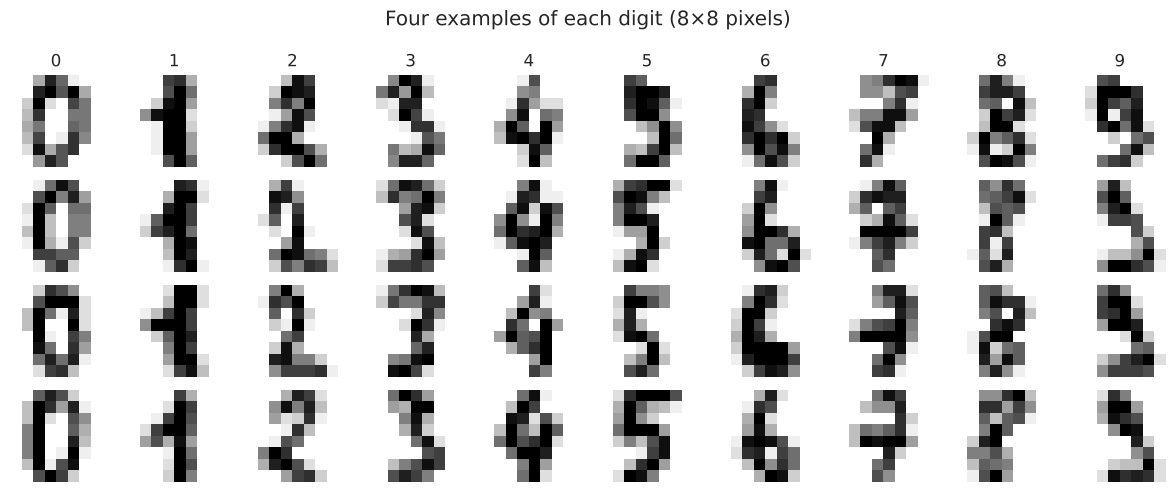

In [6]:
fig, axes = plt.subplots(4, 10, figsize=(12, 5))
for digit in range(10):
    idx = np.where(d.target == digit)[0][:4]
    for row, i in enumerate(idx):
        axes[row, digit].imshow(d.images[i], cmap="gray_r"); axes[row, digit].axis("off")
    axes[0, digit].set_title(str(digit))
fig.suptitle("Four examples of each digit (8×8 pixels)"); plt.tight_layout();

At 8×8 resolution handwriting styles still differ a lot: compare the 1s and the 7s. Next, the **mean image** per class: what a template-matching model would learn.

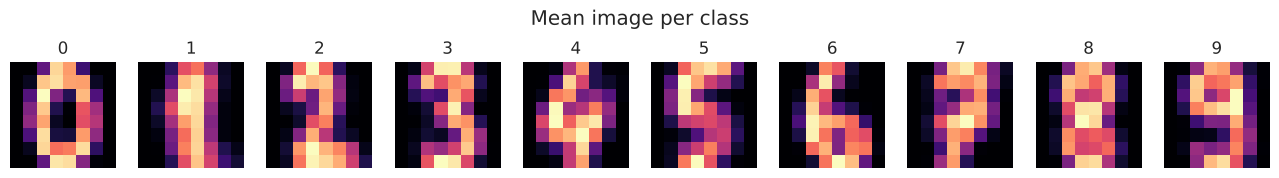

In [7]:
fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for digit, a in enumerate(axes):
    a.imshow(d.images[d.target == digit].mean(0), cmap="magma"); a.set_title(digit); a.axis("off")
fig.suptitle("Mean image per class"); plt.tight_layout();

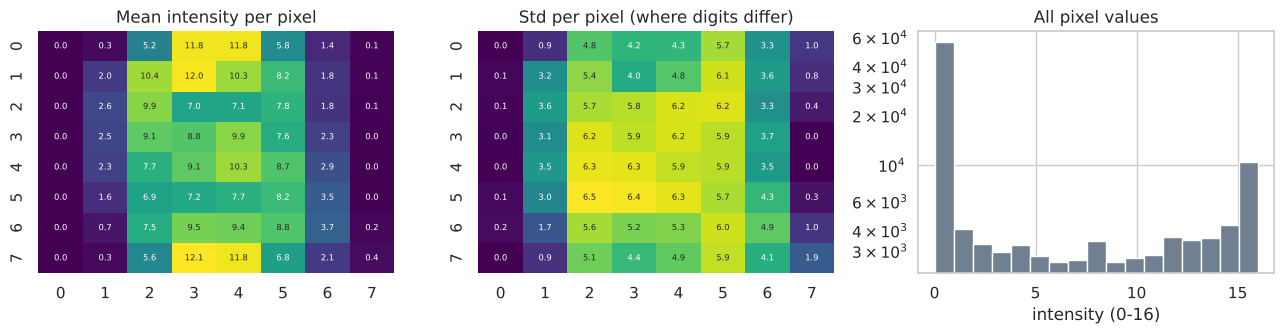

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
sns.heatmap(d.images.mean(0), ax=axes[0], cmap="viridis", annot=True, fmt=".1f", cbar=False, annot_kws={"size": 6}); axes[0].set_title("Mean intensity per pixel")
sns.heatmap(d.images.std(0), ax=axes[1], cmap="viridis", annot=True, fmt=".1f", cbar=False, annot_kws={"size": 6}); axes[1].set_title("Std per pixel (where digits differ)")
axes[2].hist(d.data.ravel(), bins=17, color="slategray"); axes[2].set(title="All pixel values", xlabel="intensity (0-16)", yscale="log")
plt.tight_layout();

Two things stand out:
- **Pixel values are bimodal**: most pixels are background (0) or full ink (16). We scale to [0, 1] by dividing by 16.
- **Variation is concentrated in the centre.** The border is almost empty, so a digit shifted by one pixel moves ink into positions the flat models rarely saw. Section 12 measures exactly that weakness.

**Ink per digit** (how many pixels are "on") is a quick sanity feature:

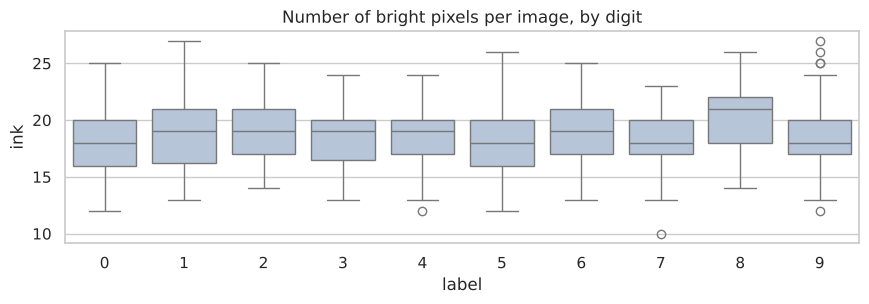

label,0,1,2,3,4,5,6,7,8,9
mean,18.0225,18.9670,18.9548,18.2951,18.8122,18.0824,19.0718,18.3296,20.2931,18.6889
std,3.0605,2.9915,2.4187,2.4180,2.2206,2.4379,2.5365,2.3290,2.5716,2.7367
min,12.0000,13.0000,14.0000,13.0000,12.0000,12.0000,13.0000,10.0000,14.0000,12.0000
max,25.0000,27.0000,25.0000,24.0000,24.0000,26.0000,25.0000,23.0000,26.0000,27.0000


In [9]:
df["ink"] = (d.data > 8).sum(1)
plt.figure(figsize=(9, 3.2)); sns.boxplot(data=df, x="label", y="ink", color="lightsteelblue")
plt.title("Number of bright pixels per image, by digit"); plt.tight_layout();
df.groupby("label").ink.describe()[["mean", "std", "min", "max"]].T

Average ink is almost identical across digits (about 18 to 20 bright pixels; 8s use slightly more), and the ranges overlap heavily. A global feature such as total ink can't separate classes, so the model has to learn shape.

## 4. Train / validation / test split

Stratified 70 / 10 / 20. The validation set drives early stopping; the test set is touched only for final numbers.

In [10]:
x_tr, y_tr, x_val, y_val, x_te, y_te = load_data()
split = pd.DataFrame({s: pd.Series(y).value_counts().sort_index() for s, y in [("train", y_tr), ("validation", y_val), ("test", y_te)]})
print("tensor shape (N, C, H, W):", x_tr.shape, " value range:", x_tr.min(), "-", x_tr.max())
split.T.assign(total=split.sum())

tensor shape (N, C, H, W): (1257, 1, 8, 8)  value range: 0.0 - 1.0

,0,1,2,3,4,5,6,7,8,9,total
train,124,128,124,128,127,127,127,125,121,126,1257
validation,18,18,18,18,18,18,18,18,18,18,180
test,36,36,35,37,36,37,36,36,35,36,360


## 5. Baselines on flat pixels

In [11]:
flat = lambda a: a.reshape(len(a), -1)
rows, base = [], {}
for name, m in [("Logistic regression", LogisticRegression(max_iter=3000)), ("MLP (128 hidden)", MLPClassifier((128,), max_iter=600, random_state=0))]:
    t0 = time.time(); m.fit(flat(x_tr), y_tr); secs = time.time() - t0
    p = m.predict_proba(flat(x_te)); base[name] = m
    rows.append({"model": name, "accuracy": accuracy_score(y_te, p.argmax(1)), "macro_f1": f1_score(y_te, p.argmax(1), average="macro"),
                 "log_loss": log_loss(y_te, p), "fit_seconds": secs})
pd.DataFrame(rows).set_index("model")

,accuracy,macro_f1,log_loss,fit_seconds
model,,,,
Logistic regression,0.9667,0.9665,0.1844,0.0424
MLP (128 hidden),0.9778,0.9779,0.1347,1.5376


Strong baselines: 96–98% on clean data. The bar for the CNN is not clean accuracy; it is accuracy *plus* robustness and calibrated confidence.

## 6. Building blocks: convolution via im2col

A convolution slides a 3×3 filter over the image. Looping over every position is slow in Python, so `im2col` unrolls every 3×3 patch into a row of a matrix. The convolution then becomes one matrix multiply. First, check it against a naive loop:

In [12]:
rng = np.random.default_rng(0)
x = rng.normal(size=(2, 3, 5, 5))
conv = Conv2D(3, 4, k=3, pad=1, rng=rng)
fast = conv.forward(x)
xp = np.pad(x, ((0, 0), (0, 0), (1, 1), (1, 1)))
slow = np.zeros_like(fast)
for n in range(2):
    for f in range(4):
        for i in range(5):
            for j in range(5):
                slow[n, f, i, j] = (xp[n, :, i:i+3, j:j+3] * conv.params["W"][f]).sum() + conv.params["b"][f]
print("im2col matrix shape:", im2col(x, 3, 1, 1).shape, "(= 2 images × 25 positions, 3 channels × 9 weights)")
print("max |fast - slow|:", np.abs(fast - slow).max())

im2col matrix shape: (50, 27) (= 2 images × 25 positions, 3 channels × 9 weights)
max |fast - slow|: 1.3322676295501878e-15

Identical to machine precision. Now the full architecture:

In [13]:
cnn_demo = CNN()
x0 = x_tr[:4]
rows = []
for layer in cnn_demo.layers:
    x0 = layer.forward(x0)
    rows.append({"layer": type(layer).__name__, "output shape": str(x0.shape[1:]), "parameters": sum(v.size for v in layer.params.values())})
arch = pd.DataFrame(rows)
print("total parameters:", arch.parameters.sum())
arch

total parameters: 13706

,layer,output shape,parameters
0,Conv2D,"(16, 8, 8)",160
1,ReLU,"(16, 8, 8)",0
2,MaxPool2D,"(16, 4, 4)",0
3,Conv2D,"(32, 4, 4)",4640
4,ReLU,"(32, 4, 4)",0
5,MaxPool2D,"(32, 2, 2)",0
6,Flatten,"(128,)",0
7,Dense,"(64,)",8256
8,ReLU,"(64,)",0
9,Dropout,"(64,)",0


13,706 parameters, the same size class as the 128-unit MLP (64×128 + 128×10 + biases = 9,610). The two convolution layers hold only 4,800 of them. Convolution *shares* each 3×3 filter across all positions, which is what buys translation tolerance without extra parameters.

## 7. Gradient check

Backpropagation is hand-written, so it must be verified. For random weights, compare the analytic gradient with a finite-difference estimate $\frac{L(w+\epsilon) - L(w-\epsilon)}{2\epsilon}$.

In [14]:
m = CNN((1, 8, 8), 10, dropout=0.0, seed=3)
for layer in m.param_layers():  # biases start at exactly 0, which puts blank-pixel activations on the ReLU kink
    layer.params["b"] += np.random.default_rng(7).normal(0, 0.1, layer.params["b"].shape)  # where finite differences are undefined
xb, yb = x_tr[:5], y_tr[:5]
loss, g = cross_entropy(m.forward(xb, True), yb); m.backward(g)
rng = np.random.default_rng(1); rows = []
for li, layer in enumerate(m.param_layers()):
    for k, p in layer.params.items():
        for _ in range(3):
            idx = tuple(rng.integers(0, s) for s in p.shape); old = p[idx]
            p[idx] = old + 1e-5; lp, _ = cross_entropy(m.forward(xb, True), yb)
            p[idx] = old - 1e-5; lm, _ = cross_entropy(m.forward(xb, True), yb)
            p[idx] = old
            num, ana = (lp - lm) / 2e-5, layer.grads[k][idx]
            rows.append({"layer": f"{li}:{type(layer).__name__}.{k}", "numeric": num, "analytic": ana,
                         "rel_error": abs(num - ana) / max(1e-12, abs(num) + abs(ana))})
gc = pd.DataFrame(rows)
print("worst relative error:", f"{gc.rel_error.max():.2e}")
gc.head(12)

worst relative error: 1.04e-09

,layer,numeric,analytic,rel_error
0,0:Conv2D.W,0.0123,0.0123,0.0000
1,0:Conv2D.W,-0.0364,-0.0364,0.0000
2,0:Conv2D.W,-0.2181,-0.2181,0.0000
3,0:Conv2D.b,0.0967,0.0967,0.0000
4,0:Conv2D.b,-0.1056,-0.1056,0.0000
5,0:Conv2D.b,0.0593,0.0593,0.0000
6,1:Conv2D.W,0.0810,0.0810,0.0000
7,1:Conv2D.W,-0.0068,-0.0068,0.0000
8,1:Conv2D.W,-0.1811,-0.1811,0.0000
9,1:Conv2D.b,0.0166,0.0166,0.0000


Relative errors around 1e-7 or smaller mean the gradients are right (anything above about 1e-4 would signal a bug).

A subtle trap worth knowing: on a freshly initialised network all biases are 0, and the blank background pixels of a digit are also 0, so many first-layer activations sit *exactly* on the ReLU kink. A finite difference across a kink is meaningless, and the check fails even though the code is correct. Giving the biases small random values moves the activations off the kink.

## 8. Training

Two CNNs with the same seed and architecture:
- **plain**: original images only;
- **augmented**: every mini-batch is randomly shifted by up to 1 pixel in each direction.

Both use Adam (lr 2e-3, weight decay 1e-4), batch 64, dropout 0.3 and early stopping on validation loss (patience 6).

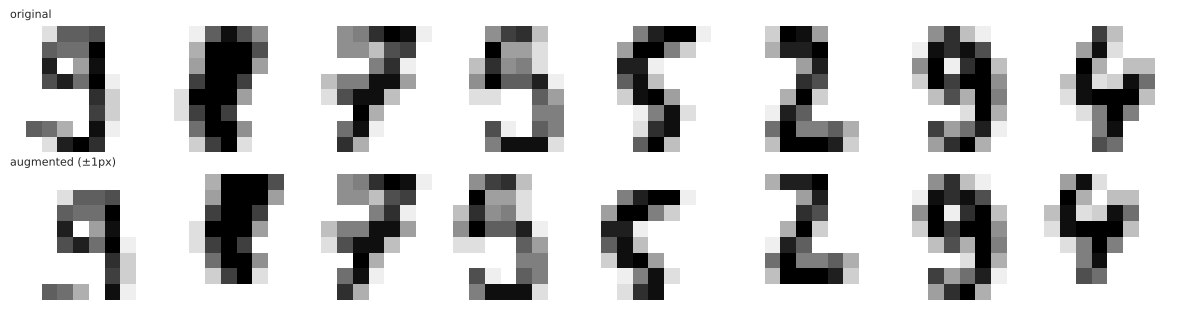

In [15]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
rng = np.random.default_rng(5)
aug = augment(x_tr[:8], rng)
for i in range(8):
    axes[0, i].imshow(x_tr[i, 0], cmap="gray_r"); axes[1, i].imshow(aug[i, 0], cmap="gray_r")
    axes[0, i].axis("off"); axes[1, i].axis("off")
axes[0, 0].set_title("original", fontsize=8, loc="left"); axes[1, 0].set_title("augmented (±1px)", fontsize=8, loc="left")
plt.tight_layout();

In [16]:
t0 = time.time()
cnn_plain = CNN(seed=0); hist_plain = train(cnn_plain, x_tr, y_tr, x_val, y_val, epochs=60, augment_data=False)
t1 = time.time()
cnn = CNN(seed=0); hist = train(cnn, x_tr, y_tr, x_val, y_val, epochs=60, augment_data=True)
t2 = time.time()
pd.DataFrame({"plain": {"epochs run": len(hist_plain["val_loss"]), "best epoch": hist_plain["best_epoch"], "best val loss": min(hist_plain["val_loss"]), "seconds": t1 - t0},
              "augmented": {"epochs run": len(hist["val_loss"]), "best epoch": hist["best_epoch"], "best val loss": min(hist["val_loss"]), "seconds": t2 - t1}})

,plain,augmented
epochs run,32.0000,44.0000
best epoch,26.0000,38.0000
best val loss,0.1140,0.0873
seconds,4.1664,6.9419


## 9. Learning curves

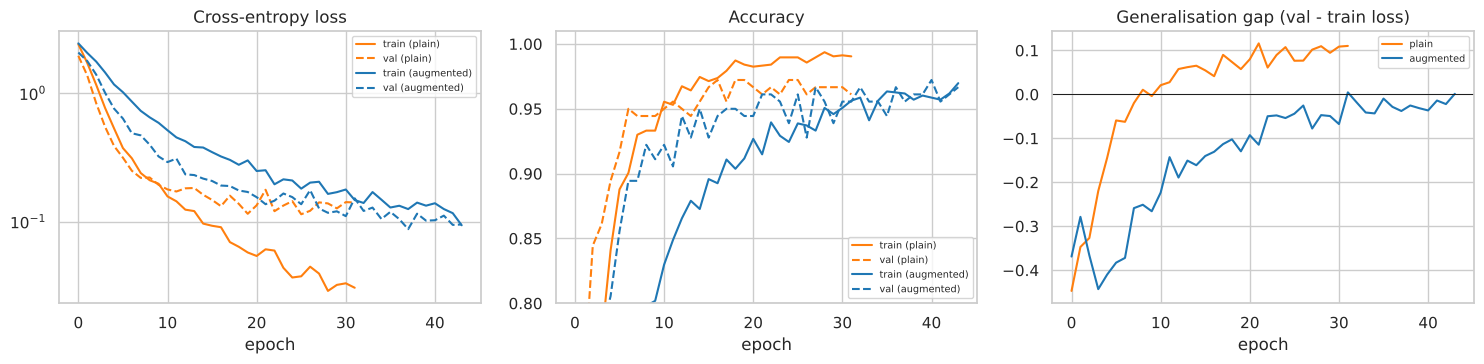

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for h, lab, c in [(hist_plain, "plain", "tab:orange"), (hist, "augmented", "tab:blue")]:
    axes[0].plot(h["train_loss"], c=c, label=f"train ({lab})"); axes[0].plot(h["val_loss"], c=c, ls="--", label=f"val ({lab})")
    axes[1].plot(h["train_acc"], c=c, label=f"train ({lab})"); axes[1].plot(h["val_acc"], c=c, ls="--", label=f"val ({lab})")
    axes[2].plot(np.array(h["val_loss"]) - np.array(h["train_loss"]), c=c, label=lab)
axes[0].set(title="Cross-entropy loss", xlabel="epoch", yscale="log"); axes[1].set(title="Accuracy", xlabel="epoch", ylim=(0.8, 1.01))
axes[2].axhline(0, c="k", lw=0.7); axes[2].set(title="Generalisation gap (val - train loss)", xlabel="epoch")
for a in axes: a.legend(fontsize=7)
plt.tight_layout();

How to read these:
- The **plain** model drives training loss toward zero fastest and its gap opens up: it is starting to memorise.
- The **augmented** model's training loss stays higher because every batch is a slightly different image. Its validation loss keeps improving for longer, so it stops later. Augmentation is acting as a regulariser.

## 10. Test metrics

In [18]:
def proba(name, x):
    if name == "CNN (plain)": return cnn_plain.predict_proba(x)
    if name == "CNN + augmentation": return cnn.predict_proba(x)
    return base[name].predict_proba(flat(x))

names = ["Logistic regression", "MLP (128 hidden)", "CNN (plain)", "CNN + augmentation"]
res = pd.DataFrame([{"model": n, "accuracy": accuracy_score(y_te, (p := proba(n, x_te)).argmax(1)),
                     "macro_f1": f1_score(y_te, p.argmax(1), average="macro"), "log_loss": log_loss(y_te, p), "ECE": ece(y_te, p),
                     "errors (of 360)": int((p.argmax(1) != y_te).sum())} for n in names]).set_index("model")
res

,accuracy,macro_f1,log_loss,ECE,errors (of 360)
model,,,,,
Logistic regression,0.9667,0.9665,0.1844,0.0722,12
MLP (128 hidden),0.9778,0.9779,0.1347,0.0140,8
CNN (plain),0.9639,0.9639,0.0843,0.0160,13
CNN + augmentation,0.9778,0.9778,0.0511,0.0193,8


- **Accuracy:** all four are within about 1.5 points on clean data. Clean accuracy alone would not justify a CNN here.
- **Log loss** is where the CNN pulls clearly ahead (about 3–4× lower than logistic regression): when it is right it is confidently right, and when wrong, less confidently wrong.
- **ECE** (expected calibration error: the gap between stated confidence and actual accuracy) is low for the MLP and both CNNs. Logistic regression is the worst calibrated.

A reliability diagram makes calibration visible:

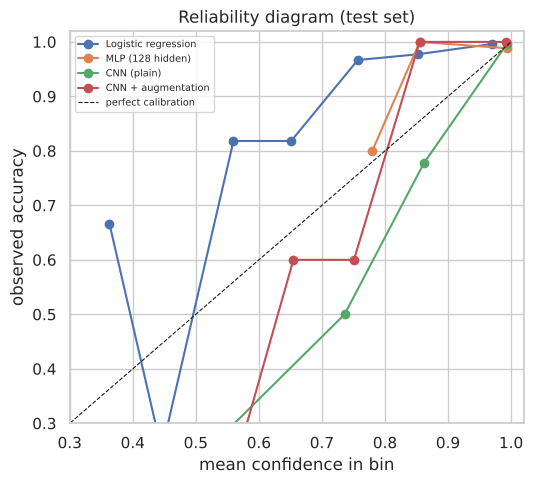

In [19]:
fig, ax = plt.subplots(figsize=(5.5, 5))
edges = np.linspace(0, 1, 11)
for n in names:
    p = proba(n, x_te); conf, ok = p.max(1), p.argmax(1) == y_te
    b = np.digitize(conf, edges[1:-1])
    xs = [conf[b == i].mean() for i in range(10) if (b == i).sum() >= 3]
    ys = [ok[b == i].mean() for i in range(10) if (b == i).sum() >= 3]
    ax.plot(xs, ys, marker="o", label=n)
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect calibration")
ax.set(xlabel="mean confidence in bin", ylabel="observed accuracy", title="Reliability diagram (test set)", xlim=(0.3, 1.02), ylim=(0.3, 1.02))
ax.legend(fontsize=7); plt.tight_layout();

## 11. Per-class performance

In [20]:
pred = cnn.predict(x_te)
rep = pd.DataFrame(classification_report(y_te, pred, output_dict=True)).T.iloc[:10]
rep.index.name = "digit"
rep

,precision,recall,f1-score,support
digit,,,,
0,1.0000,1.0000,1.0000,36.0000
1,0.9730,1.0000,0.9863,36.0000
2,0.9714,0.9714,0.9714,35.0000
3,0.9250,1.0000,0.9610,37.0000
4,1.0000,0.9722,0.9859,36.0000
5,0.9474,0.9730,0.9600,37.0000
6,1.0000,1.0000,1.0000,36.0000
7,1.0000,1.0000,1.0000,36.0000
8,0.9706,0.9429,0.9565,35.0000


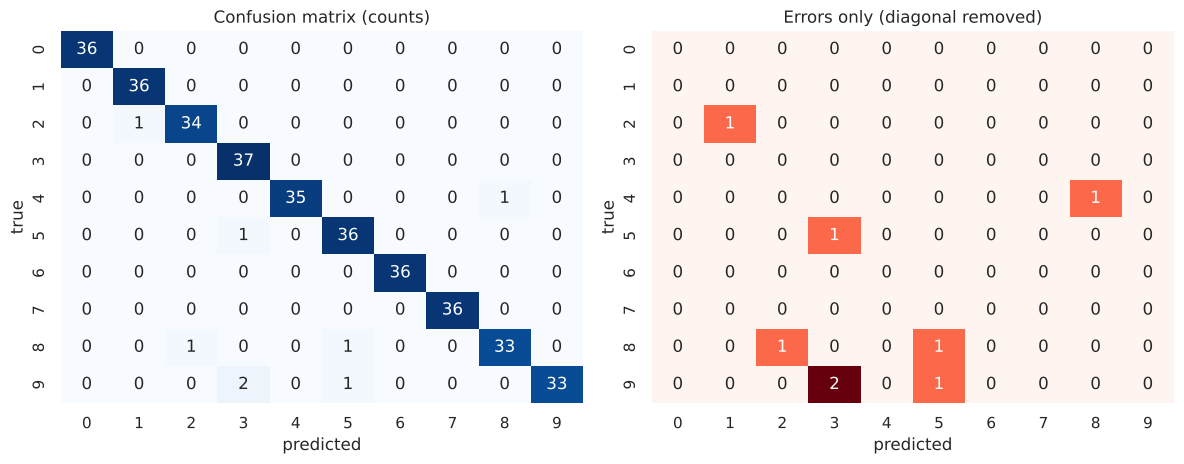

In [21]:
cm = confusion_matrix(y_te, pred)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0]); axes[0].set(title="Confusion matrix (counts)", xlabel="predicted", ylabel="true")
off = cm.copy(); np.fill_diagonal(off, 0)
sns.heatmap(off, annot=True, fmt="d", cmap="Reds", cbar=False, ax=axes[1]); axes[1].set(title="Errors only (diagonal removed)", xlabel="predicted", ylabel="true")
plt.tight_layout();

In [22]:
pairs = pd.DataFrame([(t, p, off[t, p]) for t in range(10) for p in range(10) if off[t, p] > 0], columns=["true", "predicted", "count"])
pairs.sort_values("count", ascending=False).reset_index(drop=True)

,true,predicted,count
0,9,3,2
1,4,8,1
2,2,1,1
3,5,3,1
4,8,2,1
5,8,5,1
6,9,5,1


Only 8 errors out of 360, spread thin: the only repeated confusion is a 9 read as a 3 (twice). The others (9→5, 5→3, 8→5, 8→2) are digits that share curved strokes once squeezed into 8×8 pixels: plausible mistakes, not random noise. Digits 0, 6 and 7 are perfect.

## 12. Robustness: shifted and noisy images

A deployed model sees images that are not perfectly centred. We build two corrupted copies of the test set:
- **shifted 1px**: every image moved one pixel up, down, left or right;
- **Gaussian noise σ = 0.2**: random speckle on every pixel.

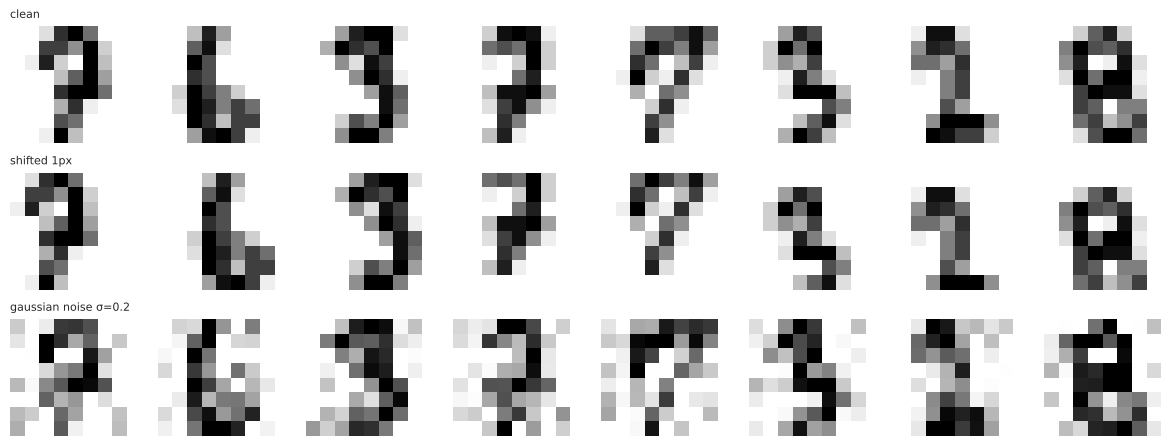

In [23]:
tests = corruptions(x_te)
fig, axes = plt.subplots(3, 8, figsize=(12, 4.6))
for r, (k, v) in enumerate(tests.items()):
    for i in range(8):
        axes[r, i].imshow(v[i, 0], cmap="gray_r", vmin=0, vmax=1); axes[r, i].axis("off")
    axes[r, 0].set_title(k, fontsize=8, loc="left")
plt.tight_layout();

In [24]:
rob = pd.DataFrame({n: {k: accuracy_score(y_te, proba(n, v).argmax(1)) for k, v in tests.items()} for n in names}).T
rob["drop when shifted"] = rob["clean"] - rob["shifted 1px"]
rob

,clean,shifted 1px,gaussian noise σ=0.2,drop when shifted
Logistic regression,0.9667,0.4306,0.9306,0.5361
MLP (128 hidden),0.9778,0.4778,0.9306,0.5000
CNN (plain),0.9639,0.6472,0.9250,0.3167
CNN + augmentation,0.9778,0.9528,0.8889,0.0250


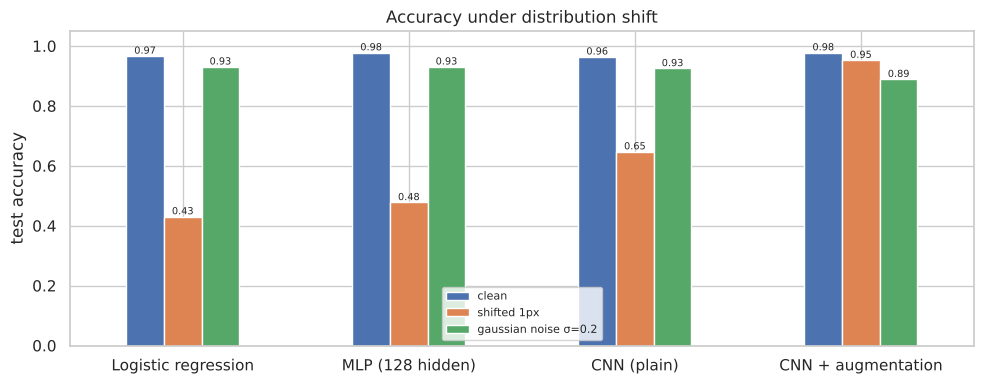

In [25]:
ax = rob[list(tests)].plot.bar(figsize=(10, 4), rot=0, color=["#4c72b0", "#dd8452", "#55a868"])
ax.set(ylabel="test accuracy", ylim=(0, 1.05), title="Accuracy under distribution shift"); ax.legend(fontsize=8)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout();

**This is the key result of the project.**
- A one-pixel shift breaks the flat models: logistic regression and the MLP fall to below 50%. They learned "ink at position (3, 4)" rather than "a loop on top of a stroke".
- The plain CNN holds up better because convolution and pooling are partly translation-tolerant, but it still loses about 30 points.
- Augmentation closes the gap: the augmented CNN keeps about 95% on shifted digits.
- **Honest trade-off:** under Gaussian noise the augmented CNN is the *worst* of the four (about 89% vs 93%). It was never shown noise, and its sharper decision boundaries make it more sensitive to speckle. The fix is to augment with noise too. Robustness is something you train for, one corruption at a time; it doesn't come free.

How accuracy degrades as noise grows:

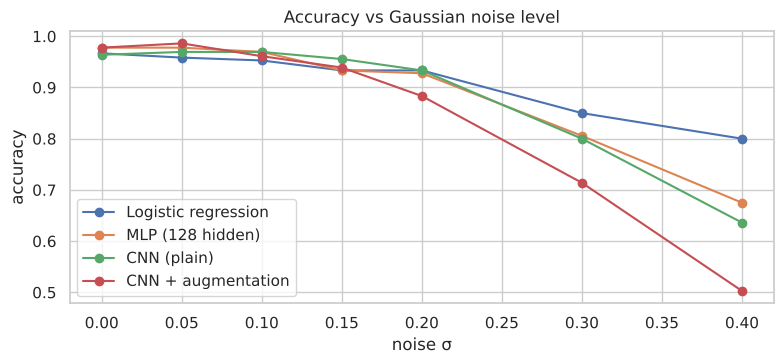

,Logistic regression,MLP (128 hidden),CNN (plain),CNN + augmentation
noise σ,,,,
0.0000,0.9667,0.9778,0.9639,0.9778
0.0500,0.9583,0.9778,0.9694,0.9861
0.1000,0.9528,0.9694,0.9694,0.9611
0.1500,0.9333,0.9333,0.9556,0.9389
0.2000,0.9333,0.9278,0.9333,0.8833
0.3000,0.8500,0.8056,0.8000,0.7139
0.4000,0.8000,0.6750,0.6361,0.5028


In [26]:
rng = np.random.default_rng(0)
sigmas = [0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4]
curve = pd.DataFrame({n: [accuracy_score(y_te, proba(n, np.clip(x_te + rng.normal(0, s, x_te.shape), 0, 1)).argmax(1)) for s in sigmas] for n in names}, index=sigmas)
curve.index.name = "noise σ"
ax = curve.plot(marker="o", figsize=(8, 3.8)); ax.set(ylabel="accuracy", title="Accuracy vs Gaussian noise level"); plt.tight_layout();
curve

## 13. Explainability: what did the network learn?

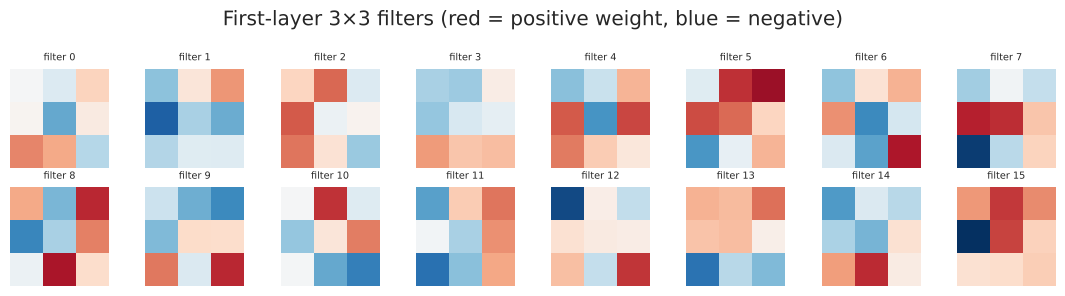

In [27]:
W = cnn.layers[0].params["W"]
fig, axes = plt.subplots(2, 8, figsize=(11, 3))
for i, a in enumerate(axes.ravel()):
    a.imshow(W[i, 0], cmap="RdBu_r", vmin=-np.abs(W).max(), vmax=np.abs(W).max()); a.set_title(f"filter {i}", fontsize=7); a.axis("off")
fig.suptitle("First-layer 3×3 filters (red = positive weight, blue = negative)"); plt.tight_layout();

Many filters are oriented edge detectors (a red side next to a blue side): they fire on stroke edges at a particular angle. Below, the 16 **feature maps** these filters produce for one test digit:

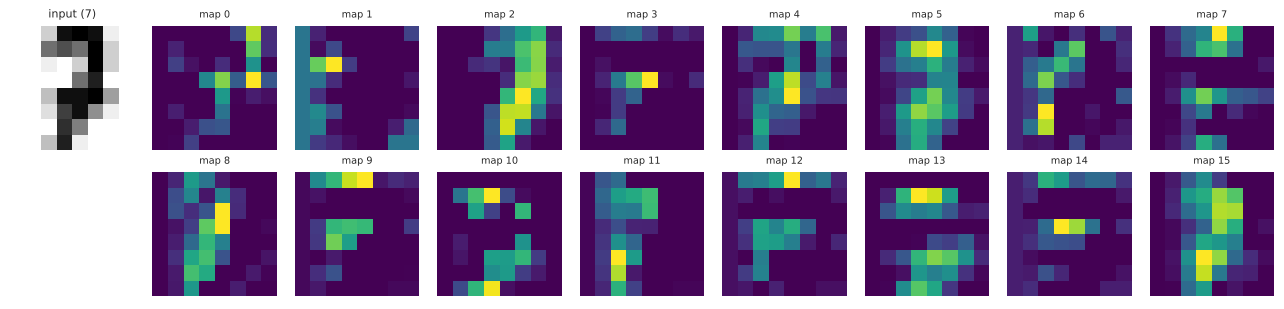

In [28]:
sample = x_te[3:4]
fmap = cnn.layers[1].forward(cnn.layers[0].forward(sample))
fig, axes = plt.subplots(2, 9, figsize=(13, 3.2))
axes[0, 0].imshow(sample[0, 0], cmap="gray_r"); axes[0, 0].set_title(f"input ({y_te[3]})", fontsize=8); axes[1, 0].axis("off")
for i in range(16):
    a = axes.ravel()[i + 1 + (i >= 8)]
    a.imshow(fmap[0, i], cmap="viridis"); a.set_title(f"map {i}", fontsize=7)
for a in axes.ravel(): a.axis("off")
plt.tight_layout();

**Saliency maps** take the gradient of the predicted class score with respect to each input pixel: bright pixels are the ones that would change the decision most if altered.

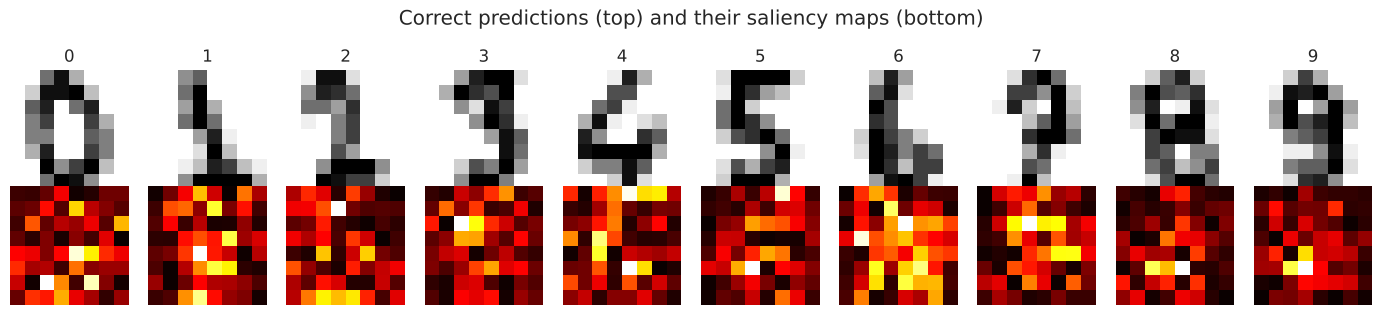

In [29]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for digit in range(10):
    i = np.where((y_te == digit) & (pred == digit))[0][0]
    axes[0, digit].imshow(x_te[i, 0], cmap="gray_r"); axes[0, digit].set_title(str(digit))
    axes[1, digit].imshow(saliency(cnn, x_te[i], digit), cmap="hot")
for a in axes.ravel(): a.axis("off")
fig.suptitle("Correct predictions (top) and their saliency maps (bottom)"); plt.tight_layout();

Saliency concentrates on and around the strokes themselves rather than on the empty border, a good sign the model is not relying on artefacts such as where the scanner cropped. Saliency at 8×8 is coarse; it tells us which pixels matter, not a human-readable reason.

## 14. Error analysis

In [30]:
probs = cnn.predict_proba(x_te)
wrong = np.where(pred != y_te)[0]
err = pd.DataFrame({"index": wrong, "true": y_te[wrong], "predicted": pred[wrong], "confidence": probs[wrong].max(1),
                    "prob of true class": probs[wrong, y_te[wrong]],
                    "runner-up": np.argsort(probs[wrong], 1)[:, -2]})
err.sort_values("confidence", ascending=False).reset_index(drop=True)

,index,true,predicted,confidence,prob of true class,runner-up
0,108,9,3,0.7760,0.1201,9
1,74,8,2,0.7197,0.2744,8
2,291,2,1,0.6464,0.2913,2
3,276,9,5,0.6115,0.3841,9
4,64,9,3,0.5846,0.4045,9
5,212,5,3,0.5825,0.3752,5
6,333,8,5,0.5177,0.2195,8
7,242,4,8,0.4620,0.2770,4


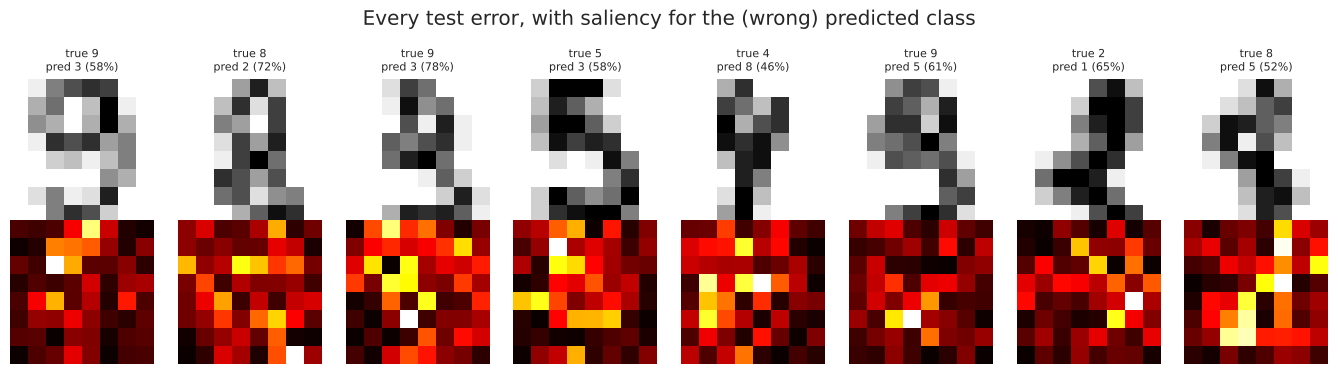

In [31]:
fig, axes = plt.subplots(2, len(wrong), figsize=(1.7 * len(wrong), 3.8))
axes = np.atleast_2d(axes).reshape(2, -1)
for a, i in zip(axes.T, wrong):
    a[0].imshow(x_te[i, 0], cmap="gray_r"); a[0].set_title(f"true {y_te[i]}\npred {pred[i]} ({probs[i].max():.0%})", fontsize=8)
    a[1].imshow(saliency(cnn, x_te[i], pred[i]), cmap="hot")
    for b in a: b.axis("off")
fig.suptitle("Every test error, with saliency for the (wrong) predicted class"); plt.tight_layout();

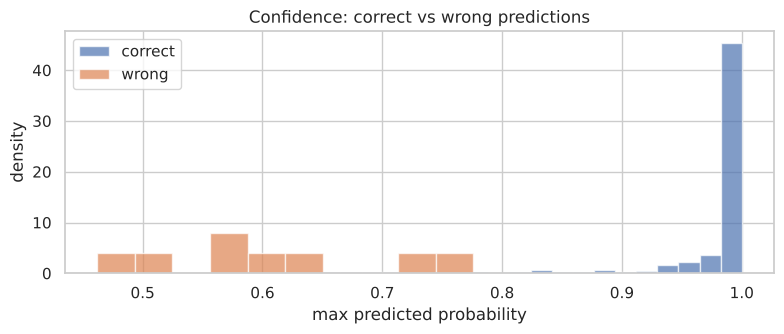

,share auto-accepted,accuracy on accepted,errors caught for review
confidence threshold,,,
0.5000,0.9944,0.9804,0.1250
0.7000,0.9694,0.9943,0.7500
0.9000,0.9222,1.0000,1.0000
0.9500,0.8806,1.0000,1.0000


In [32]:
conf_all = probs.max(1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(conf_all[pred == y_te], bins=30, alpha=0.7, label="correct", density=True)
ax.hist(conf_all[pred != y_te], bins=10, alpha=0.7, label="wrong", density=True)
ax.set(xlabel="max predicted probability", ylabel="density", title="Confidence: correct vs wrong predictions"); ax.legend(); plt.tight_layout();
thresholds = [0.5, 0.7, 0.9, 0.95]
pd.DataFrame([{"confidence threshold": t, "share auto-accepted": (conf_all >= t).mean(),
               "accuracy on accepted": (pred == y_te)[conf_all >= t].mean(), "errors caught for review": ((conf_all < t) & (pred != y_te)).sum() / max(1, (pred != y_te).sum())}
              for t in thresholds]).set_index("confidence threshold")

In every error the **runner-up is the true class**, and the model was never more than 78% confident when wrong. Several of these digits a human would also hesitate over. Because wrong predictions have visibly lower confidence than correct ones, a **confidence threshold** gives a practical human-in-the-loop policy: auto-accept the confident majority and route the rest to a person. At a 0.9 threshold, 92% of images are handled automatically with 100% accuracy on this test set, and all 8 errors go to a human. (With 360 test images that "100%" has a wide confidence interval; validate on more data before promising it.)

## 15. Next: transfer learning on real photos

Digits are a clean teaching set. Real image problems use pretrained networks. `src/vision/transfer_learning.py` fine-tunes an ImageNet-pretrained **ResNet-18** on **EuroSAT** (27,000 Sentinel-2 satellite tiles, 10 land-use classes), with flips and rotations as augmentation, mixed precision, a OneCycle schedule and **Grad-CAM** heat-maps for explainability. It needs a GPU: run `notebooks/transfer_learning_colab.ipynb` on free Google Colab (about 10 minutes for 5 epochs). The same script trains on any `folder/<class>/*.jpg` dataset.

## 16. Ethics and limitations
- **Data provenance:** the digits come from 43 writers in the original UCI collection. Handwriting from other populations, age groups or scripts may perform worse; test on representative data before any real use.
- **Robustness is not guaranteed:** section 12 shows that a model can be 98% accurate and still fail on a one-pixel shift or on noise it never saw. Always report accuracy under realistic corruptions, not only clean accuracy.
- **Calibration and abstention:** confidence is reasonably calibrated (low ECE), which makes the review threshold in section 14 meaningful. Re-check calibration after any retraining.
- **Explainability:** saliency and Grad-CAM show *where* a model looked, not *why*; they can look plausible on wrong predictions. Treat them as a debugging aid.
- **Privacy:** handwriting and satellite imagery can both be personal data (signatures, homes). Keep raw uploads out of logs; the demo app processes images in memory only.